# Weather Trend Forecasting
## Notebook 03: Baselines and a first forecasting model

Goal: forecast tomorrow's temperature (C) in six cities, using only what is known today.

Cities: Moscow, London, New Delhi, Singapore, Canberra, Buenos Aires. They cover a cold continental climate,
a maritime climate, a monsoon climate, an equatorial climate with almost no seasons, and two southern
hemisphere cities with reversed seasons.

Plan of this notebook:
1. Build one daily series per city on a full calendar
2. Build features that only use the past
3. Split the time axis into train, validation and test (no shuffling)
4. Two naive baselines: yesterday's value and the same day last year
5. A first model: Ridge regression with lags, seasonal terms and yesterday's weather
6. Compare everything on the same test days with MAE, RMSE, sMAPE and R2

The feature table built here is saved to `data/processed/city_features.csv` and reused by notebook 04,
so every model sees exactly the same rows.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

FIG = Path('../reports/figures')
PROC = Path('../data/processed')
METRICS = Path('../reports/metrics')
METRICS.mkdir(parents=True, exist_ok=True)

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e5e4e0', 'grid.linewidth': 0.6,
    'axes.edgecolor': '#8a8984', 'axes.titleweight': 'bold',
})
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
GREY = '#8a8984'
CITIES = ['Moscow', 'London', 'New Delhi', 'Singapore', 'Canberra', 'Buenos Aires']

def save(fig, name):
    fig.savefig(FIG / name)
    print('saved', FIG / name)

from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

In [2]:
clean = pd.read_csv(PROC / 'weather_clean.csv', parse_dates=['date'])
city_rows = clean[clean['location_name'].isin(CITIES)]
print(city_rows.groupby('location_name')['country'].first().loc[CITIES])
print(city_rows.groupby('location_name').size().loc[CITIES].rename('days with a snapshot'))

location_name
Moscow                  Russia
London          United Kingdom
New Delhi                India
Singapore            Singapore
Canberra             Australia
Buenos Aires         Argentina
Name: country, dtype: str
location_name
Moscow          876
London          874
New Delhi       874
Singapore       876
Canberra        875
Buenos Aires    874
Name: days with a snapshot, dtype: int64


## 1. One daily series per city

Each city is put on a full daily calendar. Days without a snapshot stay empty for the target, so they are never
scored. For the *features* those empty days are filled with the previous day's value (forward fill), which uses
only the past.

## 2. Features (all known at the end of the previous day)

| Feature | Meaning |
|---|---|
| `lag1`, `lag2`, `lag3`, `lag7` | temperature 1, 2, 3 and 7 days earlier |
| `roll7`, `roll30` | mean temperature over the previous 7 and 30 days |
| `sin1`, `cos1`, `sin2`, `cos2` | position in the year (Fourier terms), to describe the seasonal cycle |
| `humidity_lag1`, `cloud_lag1`, `wind_lag1`, `precip_lag1`, `pressure_lag1` | yesterday's weather |
| `pressure_change` | pressure yesterday minus the day before (a falling barometer often means a change) |
| `hour_lag1` | local hour of yesterday's snapshot (the snapshot time drift from notebook 01) |

Every lag is created with `shift`, which moves values forward in time, so a row never sees its own day or a later one.
The Fourier terms only use the calendar date, which is known in advance.

`lag365` (the same day last year) is kept only for the seasonal naive baseline. It is not a model feature,
because it does not exist for the first year of training data.

In [3]:
weather_cols = ['temperature_celsius', 'humidity', 'cloud', 'wind_kph', 'precip_mm', 'pressure_mb', 'local_hour']

def build_features(city):
    s = city_rows[city_rows['location_name'] == city].set_index('date')[weather_cols].sort_index()
    cal = pd.date_range(s.index.min(), s.index.max(), freq='D')
    s = s.reindex(cal)
    past = s.ffill()
    t = past['temperature_celsius']

    f = pd.DataFrame(index=cal)
    f['city'] = city
    f['y'] = s['temperature_celsius']
    for k in [1, 2, 3, 7]:
        f[f'lag{k}'] = t.shift(k)
    f['roll7'] = t.shift(1).rolling(7).mean()
    f['roll30'] = t.shift(1).rolling(30).mean()
    doy = cal.day_of_year / 365.25
    for k in [1, 2]:
        f[f'sin{k}'] = np.sin(2 * np.pi * k * doy)
        f[f'cos{k}'] = np.cos(2 * np.pi * k * doy)
    for c, name in [('humidity', 'humidity_lag1'), ('cloud', 'cloud_lag1'), ('wind_kph', 'wind_lag1'),
                    ('precip_mm', 'precip_lag1'), ('pressure_mb', 'pressure_lag1'), ('local_hour', 'hour_lag1')]:
        f[name] = past[c].shift(1)
    f['pressure_change'] = past['pressure_mb'].shift(1) - past['pressure_mb'].shift(2)
    f['lag365'] = t.shift(365)
    f['target_missing'] = s['temperature_celsius'].isna()
    return f

feats = pd.concat([build_features(c) for c in CITIES])
feats.index.name = 'date'
FEATURES = ['lag1', 'lag2', 'lag3', 'lag7', 'roll7', 'roll30', 'sin1', 'cos1', 'sin2', 'cos2',
            'humidity_lag1', 'cloud_lag1', 'wind_lag1', 'precip_lag1', 'pressure_lag1', 'pressure_change', 'hour_lag1']
print(feats.shape)
print('calendar days without a snapshot, per city:')
print(feats.groupby('city')['target_missing'].sum().loc[CITIES])

(5286, 21)
calendar days without a snapshot, per city:
city
Moscow          5
London          7
New Delhi       7
Singapore       5
Canberra        6
Buenos Aires    7
Name: target_missing, dtype: int64


### Leakage check on the features

For a few random rows, the lag values are recomputed directly from the cleaned data, by date, and compared.
If any feature came from the same day or the future, this would fail.

In [4]:
rng = np.random.default_rng(0)
checked = 0
for _ in range(200):
    city = CITIES[rng.integers(len(CITIES))]
    day = feats.index[rng.integers(400, 800)]
    row = feats[(feats.index == day) & (feats['city'] == city)]
    prev = city_rows[(city_rows['location_name'] == city) & (city_rows['date'] == day - pd.Timedelta(days=1))]
    if row.empty or prev.empty:
        continue
    assert np.isclose(row['lag1'].iloc[0], prev['temperature_celsius'].iloc[0])
    assert np.isclose(row['humidity_lag1'].iloc[0], prev['humidity'].iloc[0])
    checked += 1
print('rows checked, all lag1 values equal the previous day:', checked)

rows checked, all lag1 values equal the previous day:

 200


## 3. Chronological split

The same three windows are used in every notebook. Nothing is shuffled.
- **train:** up to 2026-04-16, to fit the models
- **validation:** 2026-04-17 to 2026-07-15 (90 days), to choose settings
- **test:** 2026-07-16 to 2026-10-13 (the last 90 days), used once at the end

The first 30 days of each city are dropped because `roll30` needs 30 past days.
Note that the test window is one season only: northern late summer and early autumn, southern late winter and early spring.

In [5]:
VAL_START = pd.Timestamp('2026-04-17')
TEST_START = pd.Timestamp('2026-07-16')
feats['split'] = np.where(feats.index < VAL_START, 'train', np.where(feats.index < TEST_START, 'val', 'test'))

usable = feats.dropna(subset=FEATURES).copy()
usable = usable[~usable['target_missing']]
usable.reset_index().to_csv(PROC / 'city_features.csv', index=False)
print('saved', PROC / 'city_features.csv', usable.shape)
usable.groupby(['city', 'split']).size().unstack()[['train', 'val', 'test']].loc[CITIES]

saved ../data/processed/city_features.csv (5070, 22)


split,train,val,test
city,,,
Moscow,667,90,89
London,665,90,89
New Delhi,665,90,89
Singapore,667,90,89
Canberra,667,90,89
Buenos Aires,665,90,89


### Sanity check: are the seasons the right way round?

Northern cities should be warmer in July than in January, southern cities the opposite, and Singapore about the same.

In [6]:
train = usable[usable['split'] == 'train']
season = train.groupby(['city', train.index.month])['y'].mean().unstack()[[1, 7]].loc[CITIES]
season.columns = ['January mean', 'July mean']
season['July minus January'] = season['July mean'] - season['January mean']
season.round(1)

,January mean,July mean,July minus January
city,,,
Moscow,-5.1,25.1,30.2
London,4.3,20.3,16.1
New Delhi,18.3,34.2,15.9
Singapore,29.4,30.3,0.9
Canberra,23.6,6.2,-17.4
Buenos Aires,21.3,7.9,-13.4


## 4. Metrics

- **MAE**: average size of the error, in C. The main metric because it is easy to explain.
- **RMSE**: like MAE but punishes large misses more.
- **sMAPE**: error relative to the size of the temperature, in %. It becomes unstable when temperatures are near
  0 C, so it is reported but not used to rank models.
- **R2**: share of the day-to-day variation in the test window that the forecast explains. In a short window
  where temperature barely moves (Singapore), R2 can be low or negative even when the errors are small.

In [7]:
def metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    e = y - p
    denom = np.abs(y) + np.abs(p)
    return {
        'MAE': np.mean(np.abs(e)),
        'RMSE': np.sqrt(np.mean(e ** 2)),
        'sMAPE': 100 * np.mean(np.where(denom > 0, 2 * np.abs(e) / denom, 0)),
        'R2': r2_score(y, p),
    }

## 5. Baselines

- **Naive:** tomorrow will be the same as today (`lag1`).
- **Seasonal naive:** tomorrow will be the same as the same date last year (`lag365`). Available for the whole
  validation and test windows.

Any model worth using has to beat both on the same days.

In [8]:
rows = []
for split in ['val', 'test']:
    part = usable[usable['split'] == split]
    for city in CITIES:
        c = part[part['city'] == city]
        rows.append({'split': split, 'city': city, 'model': 'naive (yesterday)', **metrics(c['y'], c['lag1'])})
        rows.append({'split': split, 'city': city, 'model': 'seasonal naive (last year)', **metrics(c['y'], c['lag365'])})
baselines = pd.DataFrame(rows)
baselines[baselines['split'] == 'val'].pivot(index='city', columns='model', values='MAE').loc[CITIES].round(2)

model,naive (yesterday),seasonal naive (last year)
city,,
Moscow,2.44,7.06
London,1.73,4.21
New Delhi,2.28,3.30
Singapore,2.10,1.97
Canberra,1.86,5.98
Buenos Aires,2.52,3.71


On validation, the seasonal naive baseline is much worse than the naive one in five cities. One year apart, the
weather on a given date is quite different, and the snapshot hour also moved by about 3 hours in that year.
Singapore is the exception (1.97 vs 2.10 C): with almost no seasons and no big weather swings, last year's value
is about as good a guess as yesterday's.

## 6. Ridge regression

Ridge is a linear model with a penalty that keeps coefficients small. It is a good first model: fast, easy to explain,
and with the lag features it can learn how much of today's value carries over to tomorrow.

Choices:
- The model predicts the **change from yesterday** (`y - lag1`) and then adds `lag1` back. With `lag1` as a feature
  this is mathematically the same for a linear model, but it makes the coefficients easier to read and keeps the
  setup identical to the tree models in notebook 04.
- Features are standardized inside a pipeline, so the scaler is fit only on the rows the model is trained on.
- One model per city. The penalty `alpha` is chosen on the validation window from four values.
- For the test forecast the model is refit on train + validation with that `alpha`, then predicts each test day
  from the real values of the day before (one step ahead). The model is not refit during the test window.

In [9]:
ALPHAS = [0.1, 1, 10, 100]

def fit_ridge(df, alpha):
    model = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    model.fit(df[FEATURES], df['y'] - df['lag1'])
    return model

def predict(model, df):
    return model.predict(df[FEATURES]) + df['lag1'].values

choice = {}
val_rows = []
for city in CITIES:
    c = usable[usable['city'] == city]
    tr, va = c[c['split'] == 'train'], c[c['split'] == 'val']
    scores = {a: metrics(va['y'], predict(fit_ridge(tr, a), va))['MAE'] for a in ALPHAS}
    choice[city] = min(scores, key=scores.get)
    val_rows.append({'city': city, **{f'alpha={a}': round(m, 3) for a, m in scores.items()}, 'chosen': choice[city]})
pd.DataFrame(val_rows).set_index('city')

,alpha=0.1,alpha=1,alpha=10,alpha=100,chosen
city,,,,,
Moscow,2.439,2.428,2.380,2.309,100.0
London,1.661,1.656,1.622,1.590,100.0
New Delhi,2.068,2.070,2.078,2.101,0.1
Singapore,1.601,1.600,1.587,1.581,100.0
Canberra,1.716,1.710,1.680,1.684,10.0
Buenos Aires,2.047,2.046,2.038,2.041,10.0


In [10]:
preds = []
rows = []
for city in CITIES:
    c = usable[usable['city'] == city]
    trva, te = c[c['split'] != 'test'], c[c['split'] == 'test']
    model = fit_ridge(trva, choice[city])
    p = predict(model, te)
    rows.append({'split': 'test', 'city': city, 'model': 'ridge', **metrics(te['y'], p)})
    preds.append(pd.DataFrame({'city': city, 'y': te['y'], 'naive': te['lag1'], 'seasonal_naive': te['lag365'], 'ridge': p}))

test_preds = pd.concat(preds)
test_preds.reset_index().to_csv(PROC / 'test_predictions_03.csv', index=False)
results = pd.concat([baselines[baselines['split'] == 'test'], pd.DataFrame(rows)])
results.to_csv(METRICS / '03_test_metrics.csv', index=False)

mae = results.pivot(index='city', columns='model', values='MAE').loc[CITIES]
mae['ridge vs naive (%)'] = 100 * (mae['ridge'] / mae['naive (yesterday)'] - 1)
mae.round(2)

model,naive (yesterday),ridge,seasonal naive (last year),ridge vs naive (%)
city,,,,
Moscow,1.96,1.77,3.87,-9.65
London,2.11,1.89,2.78,-10.75
New Delhi,1.65,1.77,3.61,7.11
Singapore,0.81,1.16,2.04,42.01
Canberra,2.40,2.13,3.65,-11.28
Buenos Aires,2.29,2.36,3.79,3.05


In [11]:
full = results.set_index(['city', 'model'])[['MAE', 'RMSE', 'sMAPE', 'R2']].round(3)
full.loc[CITIES]

MAE   RMSE   sMAPE     R2
city         model                                                  
Moscow       naive (yesterday)           1.958  2.530  14.075  0.647
             seasonal naive (last year)  3.869  4.993  25.218 -0.376
             ridge                       1.769  2.272  12.944  0.715
London       naive (yesterday)           2.112  2.601  13.689 -0.107
             seasonal naive (last year)  2.775  3.590  18.576 -1.109
             ridge                       1.885  2.314  12.341  0.124
New Delhi    naive (yesterday)           1.648  2.216   5.028  0.382
             seasonal naive (last year)  3.612  4.482  11.365 -1.527
             ridge                       1.765  2.279   5.415  0.347
Singapore    naive (yesterday)           0.813  1.494   2.783 -0.388
             seasonal naive (last year)  2.036  2.401   6.809 -2.587
             ridge                       1.155  1.513   3.892 -0.423
Canberra     naive (yesterday)           2.401  3.497  19.613  0.199
             seasonal naive (last year)  3.652  4.523  29.658 -0.339
             ridge                       2.130  2.968  16.846  0.423
Buenos Aires naive (yesterday)           2.293  2.952  21.564  0.293
             seasonal naive (last year)  3.787  4.563  35.633 -0.690
             ridge                       2.363  2.845  22.166  0.343

In [12]:
avg = results.groupby('model')[['MAE', 'RMSE', 'sMAPE', 'R2']].mean().round(3)
print('average over the six cities (test window):')
avg

average over the six cities (test window):


,MAE,RMSE,sMAPE,R2
model,,,,
naive (yesterday),1.871,2.548,12.792,0.171
ridge,1.845,2.365,12.267,0.255
seasonal naive (last year),3.288,4.092,21.210,-1.105


### A check before trusting the result

A rule I follow is to look for leakage when a result looks too good. A one-day-ahead temperature forecast that is
much more than about 30% better than "same as yesterday" would be suspicious. The improvement printed above
is checked here.

In [13]:
gain = 1 - mae['ridge'] / mae['naive (yesterday)']
print('largest improvement over naive:', round(gain.max() * 100, 1), '% (', gain.idxmax(), ')')
print('flag for review:', bool((gain > 0.3).any()))

largest improvement over naive: 11.3 % ( Canberra )
flag for review: False


saved ../reports/figures/03_test_forecast_ridge.png


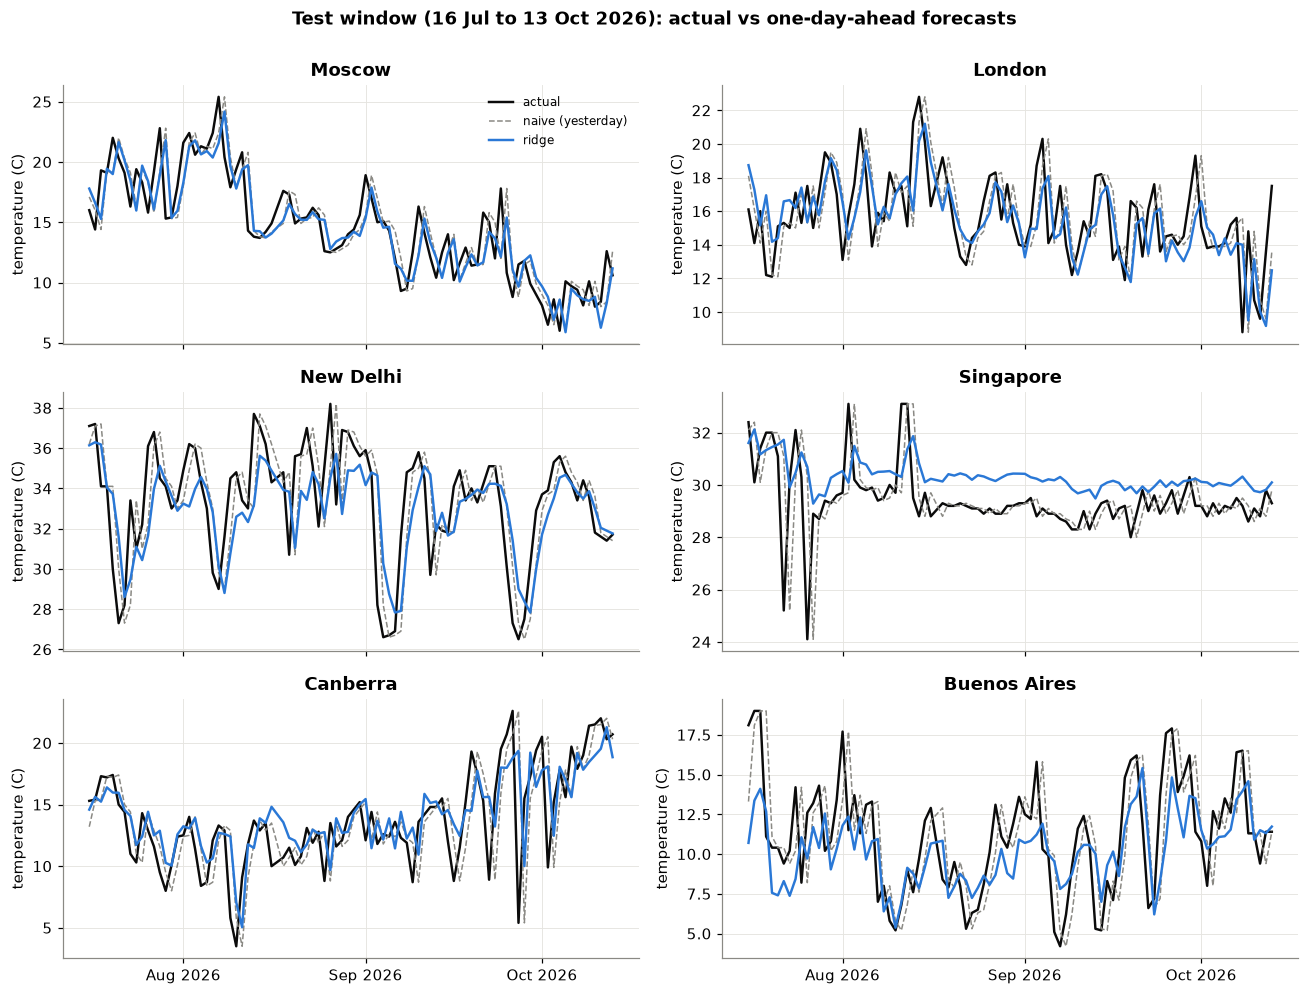

In [14]:
fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True)
for ax, city in zip(axes.flat, CITIES):
    c = test_preds[test_preds['city'] == city]
    ax.plot(c.index, c['y'], color='#0b0b0b', linewidth=1.6, label='actual')
    ax.plot(c.index, c['naive'], color=GREY, linewidth=1, linestyle='--', label='naive (yesterday)')
    ax.plot(c.index, c['ridge'], color=PALETTE[0], linewidth=1.6, label='ridge')
    ax.set_title(city)
    ax.set_ylabel('temperature (C)')
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle('Test window (16 Jul to 13 Oct 2026): actual vs one-day-ahead forecasts', y=1.0, fontweight='bold')
fig.tight_layout()
save(fig, '03_test_forecast_ridge.png')
plt.show()

saved ../reports/figures/03_test_mae_baselines_ridge.png


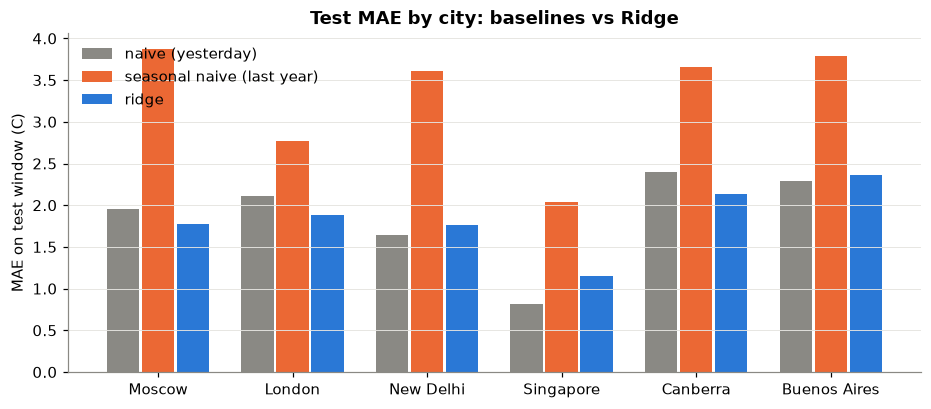

In [15]:
order = ['naive (yesterday)', 'seasonal naive (last year)', 'ridge']
x = np.arange(len(CITIES))
fig, ax = plt.subplots(figsize=(10, 4))
for i, (m, color) in enumerate(zip(order, [GREY, PALETTE[1], PALETTE[0]])):
    ax.bar(x + (i - 1) * 0.26, mae.loc[CITIES, m], width=0.24, color=color, label=m)
ax.set_xticks(x, CITIES)
ax.set_ylabel('MAE on test window (C)')
ax.set_title('Test MAE by city: baselines vs Ridge')
ax.legend(frameon=False)
ax.grid(axis='x', visible=False)
save(fig, '03_test_mae_baselines_ridge.png')
plt.show()

### Ridge coefficients

Because features are standardized, the size of a coefficient shows how much the model relies on it
(change in predicted temperature, in C, for one standard deviation of the feature). Shown for London.

saved ../reports/figures/03_ridge_coefficients_london.png


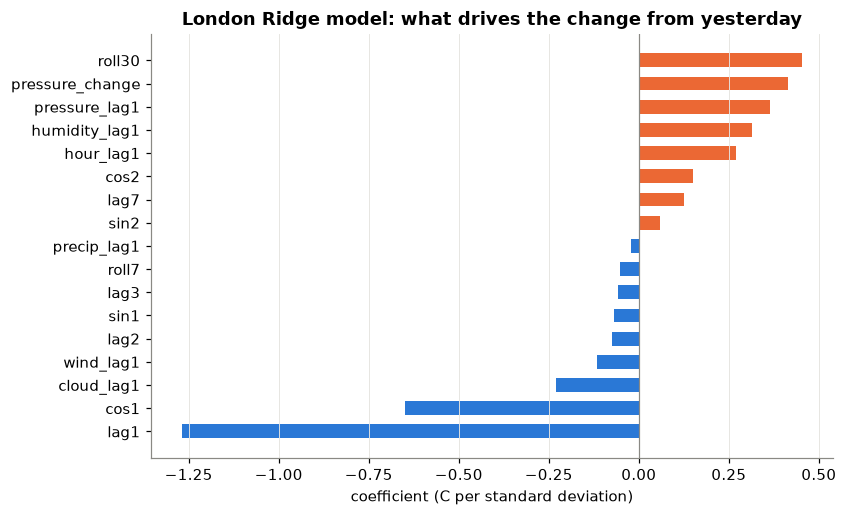

In [16]:
c = usable[(usable['city'] == 'London') & (usable['split'] != 'test')]
coefs = pd.Series(fit_ridge(c, choice['London'])[-1].coef_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(coefs.index, coefs.values, color=np.where(coefs.values > 0, PALETTE[1], PALETTE[0]), height=0.6)
ax.axvline(0, color=GREY, linewidth=0.8)
ax.set_xlabel('coefficient (C per standard deviation)')
ax.set_title('London Ridge model: what drives the change from yesterday')
ax.grid(axis='y', visible=False)
save(fig, '03_ridge_coefficients_london.png')
plt.show()

## Summary

All numbers are from the test window (16 Jul to 13 Oct 2026, 89 days per city after removing 17 August), used once.

- **Naive (yesterday) is a hard baseline.** Its average MAE over the six cities is 1.87 C.
- **Seasonal naive (last year) is much worse** in every city on the test window (average MAE 3.29 C).
- **Ridge beats naive in three cities:** Canberra (2.13 vs 2.40 C, 11% better), London (1.89 vs 2.11) and Moscow
  (1.77 vs 1.96). It does **not** beat naive in New Delhi (1.77 vs 1.65), Buenos Aires (2.36 vs 2.29) or
  Singapore (1.16 vs 0.81).
- **Singapore needs a warning.** From September 2026 its readings are almost constant (monthly standard deviation
  0.5 C in September and 0.3 C in October, against about 2 C in earlier months). Several other tropical locations
  show the same drop, which may be a change in the data source. A model trained on normal variability sits
  about 1 C too high on these flat days, while "same as yesterday" is nearly perfect.
- **Averaged over the cities**, Ridge is only slightly better than naive: MAE 1.85 vs 1.87 C, RMSE 2.37 vs 2.55 C.
  Its RMSE is lower in four cities, so it avoids some of the largest misses.
- **R2 is low or negative** for several cities and methods. Within one 90-day window the seasonal swing is small,
  so most of what is left is day-to-day weather.
- The largest gain over naive is 11.3%, well below the 30% level where leakage would be suspected.
- In validation the penalty `alpha` often went to the largest value tried (100), which means the model prefers to
  stay close to "same as yesterday".

Notebook 04 tries models that can learn non-linear patterns, and combines them.